# BigMart Sales Project

This notebook focuses on data loading, cleaning, and a simple exploratory analysis of the BigMart training data.

The goal here is to prepare a clean dataset and understand the main patterns before building any machine learning models.

## 1. Imports and Setup

We start by importing the libraries used in this notebook and setting a simple plotting style.

In [1]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
pd.set_option("display.max_columns", None)

RANDOM_STATE = 42

## 2. Load the Data

The training dataset will be used for cleaning and exploration.

In [2]:
df = pd.read_csv("Train.csv")
df.head()

,Item_Identifier,Item_Weight,Item_Fat_Content,Item_Visibility,Item_Type,Item_MRP,Outlet_Identifier,Outlet_Establishment_Year,Outlet_Size,Outlet_Location_Type,Outlet_Type,Item_Outlet_Sales
0,FDA15,9.30,Low Fat,0.016047,Dairy,249.8092,OUT049,1999,Medium,Tier 1,Supermarket Type1,3735.1380
1,DRC01,5.92,Regular,0.019278,Soft Drinks,48.2692,OUT018,2009,Medium,Tier 3,Supermarket Type2,443.4228
2,FDN15,17.50,Low Fat,0.016760,Meat,141.6180,OUT049,1999,Medium,Tier 1,Supermarket Type1,2097.2700
3,FDX07,19.20,Regular,0.000000,Fruits and Vegetables,182.0950,OUT010,1998,NaN,Tier 3,Grocery Store,732.3800
4,NCD19,8.93,Low Fat,0.000000,Household,53.8614,OUT013,1987,High,Tier 3,Supermarket Type1,994.7052


In [3]:
print(f"Rows: {df.shape[0]}")
print(f"Columns: {df.shape[1]}")

Rows: 8523
Columns: 12


## 3. Quick Overview

Before cleaning anything, it is useful to check the column types, missing values, and a few summary statistics.

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8523 entries, 0 to 8522
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Item_Identifier            8523 non-null   object 
 1   Item_Weight                7060 non-null   float64
 2   Item_Fat_Content           8523 non-null   object 
 3   Item_Visibility            8523 non-null   float64
 4   Item_Type                  8523 non-null   object 
 5   Item_MRP                   8523 non-null   float64
 6   Outlet_Identifier          8523 non-null   object 
 7   Outlet_Establishment_Year  8523 non-null   int64  
 8   Outlet_Size                6113 non-null   object 
 9   Outlet_Location_Type       8523 non-null   object 
 10  Outlet_Type                8523 non-null   object 
 11  Item_Outlet_Sales          8523 non-null   float64
dtypes: float64(4), int64(1), object(7)
memory usage: 799.2+ KB


In [5]:
missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2)
}).sort_values("missing_count", ascending=False)

missing_summary

,missing_count,missing_percent
Outlet_Size,2410,28.28
Item_Weight,1463,17.17
Item_Fat_Content,0,0.00
Item_Identifier,0,0.00
Item_Visibility,0,0.00
Item_Type,0,0.00
Outlet_Identifier,0,0.00
Item_MRP,0,0.00
Outlet_Establishment_Year,0,0.00
Outlet_Location_Type,0,0.00


In [6]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Item_Identifier,8523,1559,FDW13,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Item_Weight,7060.0,NaN,NaN,NaN,12.857645,4.643456,4.555,8.77375,12.6,16.85,21.35
Item_Fat_Content,8523,5,Low Fat,5089,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Item_Visibility,8523.0,NaN,NaN,NaN,0.066132,0.051598,0.0,0.026989,0.053931,0.094585,0.328391
Item_Type,8523,16,Fruits and Vegetables,1232,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Item_MRP,8523.0,NaN,NaN,NaN,140.992782,62.275067,31.29,93.8265,143.0128,185.6437,266.8884
Outlet_Identifier,8523,10,OUT027,935,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Outlet_Establishment_Year,8523.0,NaN,NaN,NaN,1997.831867,8.37176,1985.0,1987.0,1999.0,2004.0,2009.0
Outlet_Size,6113,3,Medium,2793,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Outlet_Location_Type,8523,3,Tier 3,3350,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 4. Data Cleaning

In this section, the main cleaning steps are:

- standardize inconsistent category labels
- fill missing values with simple grouped logic
- fix zero values in `Item_Visibility`
- create a few useful features for later modeling

In [7]:
# Work on a copy so the original loaded data stays unchanged.
clean_df = df.copy()

### 4.1 Standardize `Item_Fat_Content`

This column has repeated meanings written in different ways, so we make the labels consistent.

In [8]:
clean_df["Item_Fat_Content"] = clean_df["Item_Fat_Content"].replace({
    "LF": "Low Fat",
    "low fat": "Low Fat",
    "reg": "Regular"
})

clean_df["Item_Fat_Content"].value_counts()

Item_Fat_Content
Low Fat    5517
Regular    3006
Name: count, dtype: int64

### 4.2 Fill Missing `Item_Weight`

First, missing weights are filled using the average weight of the same `Item_Identifier`.
If any values are still missing after that, the average of the same `Item_Type` is used.

In [9]:
clean_df["Item_Weight"] = clean_df["Item_Weight"].fillna(
    clean_df.groupby("Item_Identifier")["Item_Weight"].transform("mean")
)

clean_df["Item_Weight"] = clean_df["Item_Weight"].fillna(
    clean_df.groupby("Item_Type")["Item_Weight"].transform("mean")
)

clean_df["Item_Weight"].isna().sum()

np.int64(0)

### 4.3 Fill Missing `Outlet_Size`

`Outlet_Size` is filled using the most common size inside each `Outlet_Type`.
This is a simple assumption, but it is reasonable for this dataset.

In [10]:
outlet_size_mode = clean_df.groupby("Outlet_Type")["Outlet_Size"].agg(
    lambda x: x.mode().iloc[0]
)

clean_df["Outlet_Size"] = clean_df["Outlet_Size"].fillna(
    clean_df["Outlet_Type"].map(outlet_size_mode)
)

clean_df["Outlet_Size"].isna().sum()

np.int64(0)

### 4.4 Fix Zero Values in `Item_Visibility`

A visibility value of zero is unusual, so these values are replaced with the average visibility of the same item.
If that average is also zero, the overall median visibility is used as a fallback.

In [11]:
item_visibility_mean = clean_df.groupby("Item_Identifier")["Item_Visibility"].transform("mean")
overall_visibility_median = clean_df.loc[clean_df["Item_Visibility"] > 0, "Item_Visibility"].median()

zero_visibility_mask = clean_df["Item_Visibility"] == 0
replacement_visibility = item_visibility_mean.mask(item_visibility_mean == 0, overall_visibility_median)

clean_df.loc[zero_visibility_mask, "Item_Visibility"] = replacement_visibility[zero_visibility_mask]

(clean_df["Item_Visibility"] == 0).sum()

np.int64(0)

### 4.5 Create a Few Useful Features

These features are simple but helpful for later analysis and modeling.

In [12]:
clean_df["Item_Category"] = clean_df["Item_Identifier"].str[:2].map({
    "FD": "Food",
    "NC": "Non-Consumable",
    "DR": "Drinks"
})

clean_df.loc[clean_df["Item_Category"] == "Non-Consumable", "Item_Fat_Content"] = "Non-Edible"

clean_df["Outlet_Age"] = 2013 - clean_df["Outlet_Establishment_Year"]
clean_df["Item_Visibility_Mean"] = clean_df.groupby("Item_Identifier")["Item_Visibility"].transform("mean")
clean_df["Visibility_Ratio"] = clean_df["Item_Visibility"] / clean_df["Item_Visibility_Mean"]

clean_df[["Item_Category", "Outlet_Age", "Item_Visibility_Mean", "Visibility_Ratio"]].head()

,Item_Category,Outlet_Age,Item_Visibility_Mean,Visibility_Ratio
0,Food,14,0.017387,0.922960
1,Drinks,4,0.019219,1.003057
2,Food,14,0.020145,0.831990
3,Food,15,0.020365,0.750000
4,Non-Consumable,26,0.012123,0.666667


In [13]:
clean_df.isna().sum()

Item_Identifier              0
Item_Weight                  0
Item_Fat_Content             0
Item_Visibility              0
Item_Type                    0
Item_MRP                     0
Outlet_Identifier            0
Outlet_Establishment_Year    0
Outlet_Size                  0
Outlet_Location_Type         0
Outlet_Type                  0
Item_Outlet_Sales            0
Item_Category                0
Outlet_Age                   0
Item_Visibility_Mean         0
Visibility_Ratio             0
dtype: int64

## 5. Exploratory Data Analysis

Now that the main cleaning steps are done, we can look at a few patterns in the target variable and the most important features.

In [14]:
clean_df["Item_Outlet_Sales"].describe()

count     8523.000000
mean      2181.288914
std       1706.499616
min         33.290000
25%        834.247400
50%       1794.331000
75%       3101.296400
max      13086.964800
Name: Item_Outlet_Sales, dtype: float64

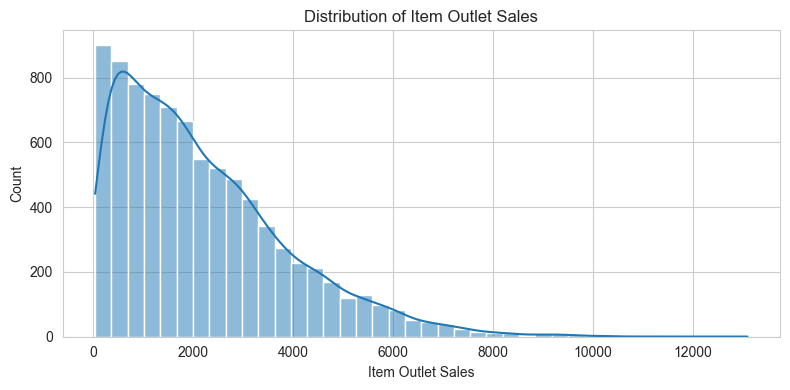

In [15]:
plt.figure(figsize=(8, 4))
sns.histplot(clean_df["Item_Outlet_Sales"], bins=40, kde=True)
plt.title("Distribution of Item Outlet Sales")
plt.xlabel("Item Outlet Sales")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

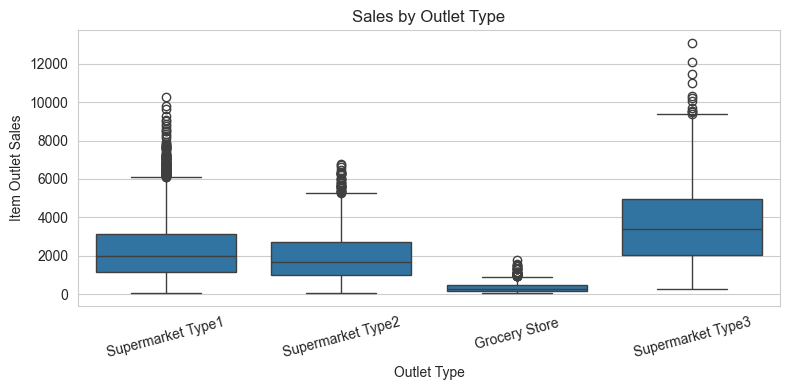

In [16]:
plt.figure(figsize=(8, 4))
sns.boxplot(data=clean_df, x="Outlet_Type", y="Item_Outlet_Sales")
plt.title("Sales by Outlet Type")
plt.xlabel("Outlet Type")
plt.ylabel("Item Outlet Sales")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

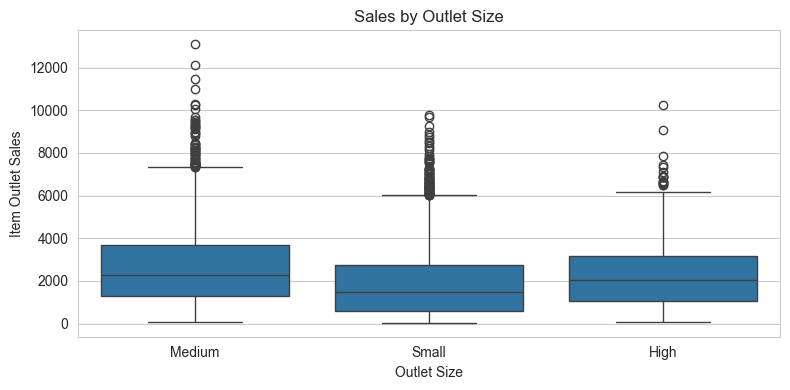

In [17]:
plt.figure(figsize=(8, 4))
sns.boxplot(data=clean_df, x="Outlet_Size", y="Item_Outlet_Sales")
plt.title("Sales by Outlet Size")
plt.xlabel("Outlet Size")
plt.ylabel("Item Outlet Sales")
plt.tight_layout()
plt.show()

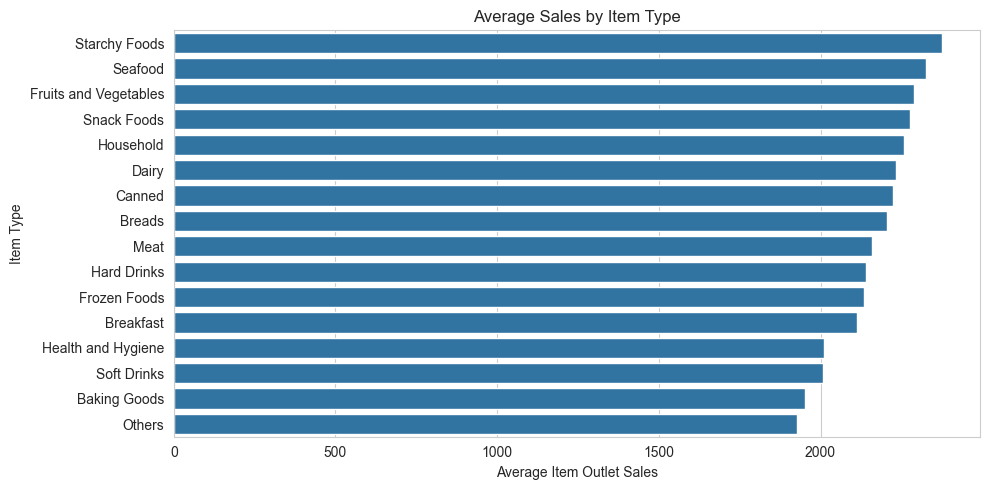

In [18]:
plt.figure(figsize=(10, 5))
category_sales = clean_df.groupby("Item_Type")["Item_Outlet_Sales"].mean().sort_values(ascending=False)
sns.barplot(x=category_sales.values, y=category_sales.index)
plt.title("Average Sales by Item Type")
plt.xlabel("Average Item Outlet Sales")
plt.ylabel("Item Type")
plt.tight_layout()
plt.show()

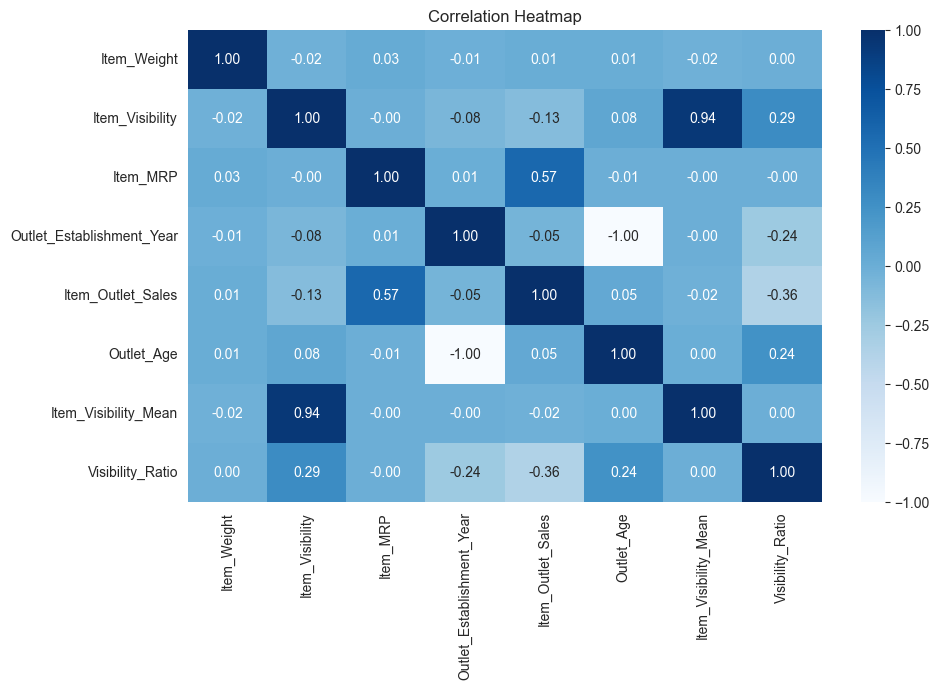

In [19]:
num_cols = clean_df.select_dtypes(include=["int64", "float64"]).columns
correlation_matrix = clean_df[num_cols].corr()

plt.figure(figsize=(10, 7))
sns.heatmap(correlation_matrix, annot=True, cmap="Blues", fmt=".2f")
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

## 6. Final Clean Dataset Check

At this point, the dataset is cleaned, feature-enriched, and ready for a separate modeling notebook.

In [20]:
clean_df.head()

,Item_Identifier,Item_Weight,Item_Fat_Content,Item_Visibility,Item_Type,Item_MRP,Outlet_Identifier,Outlet_Establishment_Year,Outlet_Size,Outlet_Location_Type,Outlet_Type,Item_Outlet_Sales,Item_Category,Outlet_Age,Item_Visibility_Mean,Visibility_Ratio
0,FDA15,9.30,Low Fat,0.016047,Dairy,249.8092,OUT049,1999,Medium,Tier 1,Supermarket Type1,3735.1380,Food,14,0.017387,0.922960
1,DRC01,5.92,Regular,0.019278,Soft Drinks,48.2692,OUT018,2009,Medium,Tier 3,Supermarket Type2,443.4228,Drinks,4,0.019219,1.003057
2,FDN15,17.50,Low Fat,0.016760,Meat,141.6180,OUT049,1999,Medium,Tier 1,Supermarket Type1,2097.2700,Food,14,0.020145,0.831990
3,FDX07,19.20,Regular,0.015274,Fruits and Vegetables,182.0950,OUT010,1998,Small,Tier 3,Grocery Store,732.3800,Food,15,0.020365,0.750000
4,NCD19,8.93,Non-Edible,0.008082,Household,53.8614,OUT013,1987,High,Tier 3,Supermarket Type1,994.7052,Non-Consumable,26,0.012123,0.666667


In [21]:
print("Final shape:", clean_df.shape)
print("Remaining missing values:", int(clean_df.isna().sum().sum()))

Final shape: (8523, 16)
Remaining missing values: 0


## 7. Stop Point

This notebook intentionally stops before encoding, train-validation splitting, or model training.

The next step will be to use `clean_df` inside a separate notebook for feature preparation and modeling.